In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, RepeatedStratifiedKFold, HalvingRandomSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from scipy.stats import randint, uniform
import mlflow
import mlflow.sklearn
import joblib
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')

In [5]:
path = "data/heart_disease_uci_preprocessed.csv"

df = pd.read_csv(path)

assert 'target' in df.columns, "Coluna 'target' não encontrada no dataset pré-processado."

for col in ['id', 'dataset']:
    if col in df.columns:
        df.drop(columns=[col], inplace=True)

print(f"Dataset shape (pré-processado): {df.shape}")
print("\nTarget (0=Sem doença, 1=Com doença):")
print(df['target'].value_counts())

df.head()

Dataset shape (pré-processado): (920, 19)

Target (0=Sem doença, 1=Com doença):
target
1    509
0    411
Name: count, dtype: int64


,age,trestbps,chol,fbs,thalch,exang,oldpeak,ca,target,sex_Male,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,63,145.0,233.0,True,150.0,False,2.3,0.0,0,True,False,False,True,False,False,False,False,False,False
1,67,160.0,286.0,False,108.0,True,1.5,3.0,1,True,False,False,False,False,False,True,False,True,False
2,67,120.0,229.0,False,129.0,True,2.6,2.0,1,True,False,False,False,False,False,True,False,False,True
3,37,130.0,250.0,False,187.0,False,3.5,0.0,0,True,False,True,False,True,False,False,False,True,False
4,41,130.0,204.0,False,172.0,False,1.4,0.0,0,False,True,False,False,False,False,False,True,True,False


In [6]:
df.describe()

,age,trestbps,chol,thalch,oldpeak,ca,target
count,920.000000,920.000000,920.000000,920.000000,920.000000,920.000000,920.000000
mean,53.510870,131.995652,199.908696,137.692391,0.853261,0.227174,0.553261
std,9.424685,18.451300,109.040171,25.145235,1.058049,0.628936,0.497426
min,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,47.000000,120.000000,177.750000,120.000000,0.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,60.000000,140.000000,267.000000,156.000000,1.500000,0.000000,1.000000
max,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,1.000000


In [7]:
null_total = df.isnull().sum().sum()
print(f"Total de valores nulos no CSV pré-processado: {null_total}")
if null_total > 0:
    print(df.isnull().sum().sort_values(ascending=False).head(10))

Total de valores nulos no CSV pré-processado: 0


In [9]:
df_engineered = df.copy()

y = df_engineered['target']
X = df_engineered.drop(columns=['target'])

eps = 1

df_engineered['age_squared'] = df_engineered['age'] ** 2

df_engineered['cholesterol_to_age'] = df_engineered['chol'] / (df_engineered['age'] + eps)

if 'thalch' in df_engineered.columns and 'age' in df_engineered.columns:
    predicted_max_hr = (220 - df_engineered['age']).clip(lower=1)
    df_engineered['max_hr_pct'] = df_engineered['thalch'] / (predicted_max_hr + eps)

if 'trestbps' in df_engineered.columns and 'chol' in df_engineered.columns:
    df_engineered['bp_chol_ratio'] = df_engineered['trestbps'] / (df_engineered['chol'] + 1)

if 'fbs' in df_engineered.columns:
    df_engineered['fbs_flag'] = df_engineered['fbs'].astype(int)

if 'exang' in df_engineered.columns:
    df_engineered['exang_flag'] = df_engineered['exang'].astype(int)

if 'thalch' in df_engineered.columns and 'trestbps' in df_engineered.columns:
    df_engineered['stress_index'] = df_engineered['thalch'] / (df_engineered['trestbps'] + eps)

if 'age' in df_engineered.columns:
    df_engineered['age_decade'] = (df_engineered['age'] // 10).astype(int)

if 'age' in df_engineered.columns and 'oldpeak' in df_engineered.columns:
    df_engineered['risk_interaction'] = df_engineered['age'] * df_engineered['oldpeak']

if 'oldpeak' in df_engineered.columns:
    df_engineered['high_st_depression_flag'] = (df_engineered['oldpeak'] > 1.0).astype(int)

new_feats = ['fbs_flag', 'exang_flag', 'bp_chol_ratio', 'max_hr_pct',
             'stress_index', 'age_decade', 'risk_interaction', 'high_st_depression_flag']
present = [c for c in new_feats if c in df_engineered.columns]
print(f"Novas features adicionadas ({len(present)}): {present}")

df_engineered.head(100)

Novas features adicionadas (8): ['fbs_flag', 'exang_flag', 'bp_chol_ratio', 'max_hr_pct', 'stress_index', 'age_decade', 'risk_interaction', 'high_st_depression_flag']


,age,trestbps,chol,fbs,thalch,exang,oldpeak,ca,target,sex_Male,...,age_squared,cholesterol_to_age,max_hr_pct,bp_chol_ratio,fbs_flag,exang_flag,stress_index,age_decade,risk_interaction,high_st_depression_flag
0,63,145.0,233.0,True,150.0,False,2.3,0.0,0,True,...,3969,3.640625,0.949367,0.619658,1,0,1.027397,6,144.9,1
1,67,160.0,286.0,False,108.0,True,1.5,3.0,1,True,...,4489,4.205882,0.701299,0.557491,0,1,0.670807,6,100.5,1
2,67,120.0,229.0,False,129.0,True,2.6,2.0,1,True,...,4489,3.367647,0.837662,0.521739,0,1,1.066116,6,174.2,1
3,37,130.0,250.0,False,187.0,False,3.5,0.0,0,True,...,1369,6.578947,1.016304,0.517928,0,0,1.427481,3,129.5,1
4,41,130.0,204.0,False,172.0,False,1.4,0.0,0,False,...,1681,4.857143,0.955556,0.634146,0,0,1.312977,4,57.4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,52,128.0,255.0,False,161.0,True,0.0,1.0,1,True,...,2704,4.811321,0.952663,0.500000,0,1,1.248062,5,0.0,0
96,59,110.0,239.0,False,142.0,True,1.2,1.0,1,True,...,3481,3.983333,0.876543,0.458333,0,1,1.279279,5,70.8,1
97,60,150.0,258.0,False,157.0,False,2.6,2.0,1,False,...,3600,4.229508,0.975155,0.579151,0,0,1.039735,6,156.0,1
98,52,134.0,201.0,False,158.0,False,0.8,1.0,0,True,...,2704,3.792453,0.934911,0.663366,0,0,1.170370,5,41.6,0


In [10]:
y = df_engineered['target']
X = df_engineered.drop(columns=['target'])
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

selector_preview = SelectKBest(f_classif, k=min(25, X_train.shape[1]))
X_train_selected = selector_preview.fit_transform(X_train, y_train)

X_test_selected = selector_preview.transform(X_test)

selected_mask = selector_preview.get_support()
selected_features = [name for name, keep in zip(feature_names, selected_mask) if keep]
print(f"\nFeatures selecionadas ({len(selected_features)}):")
for i, feat in enumerate(selected_features, 1):
    print(f"{i}. {feat}")


Features selecionadas (25):
1. age
2. trestbps
3. chol
4. thalch
5. exang
6. oldpeak
7. ca
8. sex_Male
9. cp_atypical angina
10. cp_non-anginal
11. restecg_normal
12. restecg_st-t abnormality
13. slope_flat
14. slope_upsloping
15. thal_normal
16. thal_reversable defect
17. age_squared
18. cholesterol_to_age
19. max_hr_pct
20. bp_chol_ratio
21. exang_flag
22. stress_index
23. age_decade
24. risk_interaction
25. high_st_depression_flag


In [11]:
model_configs = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

trained_models = {}
results = []

for model_name, estimator in model_configs.items():
    steps = []
    if model_name == "Support Vector Machine":
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", estimator))
    pipeline = Pipeline(steps)
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = np.nan
    if hasattr(pipeline, "predict_proba"):
        y_proba = pipeline.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_proba)
    elif hasattr(pipeline, "decision_function"):
        y_scores = pipeline.decision_function(X_test)
        roc_auc = roc_auc_score(y_test, y_scores)

    print(f"=== {model_name} ===")
    print(f"Acurácia no conjunto de teste: {accuracy:.3f}")
    print(classification_report(y_test, y_pred, target_names=["Sem doença", "Com doença"]))
    print("-" * 70)

    trained_models[model_name] = pipeline
    results.append({
        "Modelo": model_name,
        "Acurácia": accuracy,
        "Precisão": precision,
        "Recall": recall,
        "F1": f1,
        "ROC AUC": roc_auc,
    })

results_df = pd.DataFrame(results)
results_df.sort_values(by="Acurácia", ascending=False).reset_index(drop=True).round(3)

=== Decision Tree ===
Acurácia no conjunto de teste: 0.766
              precision    recall  f1-score   support

  Sem doença       0.72      0.78      0.75        82
  Com doença       0.81      0.75      0.78       102

    accuracy                           0.77       184
   macro avg       0.76      0.77      0.77       184
weighted avg       0.77      0.77      0.77       184

----------------------------------------------------------------------
=== Random Forest ===
Acurácia no conjunto de teste: 0.859
              precision    recall  f1-score   support

  Sem doença       0.87      0.80      0.84        82
  Com doença       0.85      0.90      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.85      0.86       184
weighted avg       0.86      0.86      0.86       184

----------------------------------------------------------------------
=== Support Vector Machine ===
Acurácia no conjunto de teste: 0.853
              prec

,Modelo,Acurácia,Precisão,Recall,F1,ROC AUC
0,Random Forest,0.859,0.852,0.902,0.876,0.912
1,Support Vector Machine,0.853,0.844,0.902,0.872,0.919
2,Gradient Boosting,0.848,0.836,0.902,0.868,0.902
3,Decision Tree,0.766,0.811,0.755,0.782,0.768


In [ ]:
import time
from sklearn.model_selection import ParameterSampler, StratifiedKFold, cross_val_score
from scipy.stats import randint

TIME_LIMIT_MINUTES = 60
ACC_TARGET = 0.86

start_time = time.time()
deadline = start_time + TIME_LIMIT_MINUTES * 60

n_features = X_train.shape[1]
base_pipeline = Pipeline([
    ("selector", SelectKBest(score_func=f_classif, k="all")),
    ("model", RandomForestClassifier(random_state=42)),
])

param_distributions = {
    "model__n_estimators": randint(50, 151),
    "model__max_depth": [None, 2, 5, 7, 10, 15, 25],
    "model__max_features": [v for v in [2, 5, 7, 10, 15, 25] if v <= X_train.shape[1]],
    "model__max_leaf_nodes": [None] + list(range(5, 16)),
    "model__min_samples_split": randint(2, 300),   # 2 a 300
    "model__min_samples_leaf": randint(1, 300),    # 1 a 300
}

sampler = ParameterSampler(param_distributions=param_distributions, n_iter=1_000_000, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best = {
    "params": None,
    "cv_acc": -np.inf,
    "test_acc": -np.inf,
    "pipeline": None,
}

n_evaluated = 0
print(f"Iniciando busca por até {TIME_LIMIT_MINUTES} min. Alvo: acc_teste > {ACC_TARGET}.")

for i, params in enumerate(sampler, start=1):
    now = time.time()
    if now >= deadline:
        print("Tempo limite atingido; encerrando busca.")
        break

    pipeline = Pipeline([
        ("selector", SelectKBest(score_func=f_classif, k="all")),
        ("model", RandomForestClassifier(random_state=42)),
    ])
    pipeline.set_params(**params)

    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    mean_cv = float(np.mean(cv_scores))

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)

    if test_acc > best["test_acc"]:
        best.update({
            "params": params,
            "cv_acc": mean_cv,
            "test_acc": test_acc,
            "pipeline": pipeline,
        })
        elapsed = now - start_time
        print(f"[{i}] Novo melhor | acc_teste={test_acc:.4f} | acc_cv={mean_cv:.4f} | t={elapsed/60:.1f}m | params={params}")

    if i % 5 == 0:
        elapsed = now - start_time
        remaining = max(0.0, deadline - now)
        print(
            f"Iterações: {i} | melhor_acc_teste={best['test_acc']:.4f} | "
            f"decorrido={elapsed/60:.1f}m | restante≈{remaining/60:.1f}m"
        )

    n_evaluated = i

best_rf = best["pipeline"] if best["pipeline"] is not None else base_pipeline.fit(X_train, y_train)

y_pred_tuned = best_rf.predict(X_test)
y_proba_tuned = (
    best_rf.predict_proba(X_test)[:, 1]
    if hasattr(best_rf, "predict_proba") else
    (best_rf.decision_function(X_test) if hasattr(best_rf, "decision_function") else np.zeros_like(y_pred_tuned, dtype=float))
)

tuned_metrics = {
    "Acurácia": accuracy_score(y_test, y_pred_tuned),
    "Precisão": precision_score(y_test, y_pred_tuned),
    "Recall": recall_score(y_test, y_pred_tuned),
    "F1": f1_score(y_test, y_pred_tuned),
    "ROC AUC": roc_auc_score(y_test, y_proba_tuned) if not np.all(y_proba_tuned == 0) else np.nan,
}

print("\nResumo da busca:")
print(f"Iterações avaliadas: {n_evaluated}")
elapsed_total = time.time() - start_time
print(f"Tempo total: {elapsed_total/60:.1f} minutos")
print(f"Melhor acurácia (teste): {tuned_metrics['Acurácia']:.4f}")
print(f"Alvo (acc > {ACC_TARGET}): {'atingido' if tuned_metrics['Acurácia'] > ACC_TARGET else 'não atingido'}")

try:
    mlflow.set_experiment("time_budget_tuning")
    with mlflow.start_run(run_name="rf_parameter_sampler_60min_4params"):
        if best["params"] is not None:
            for k, v in best["params"].items():
                mlflow.log_param(k, str(v))
        mlflow.log_metric("cv_accuracy", float(best["cv_acc"]))
        for k, v in tuned_metrics.items():
            if v is not None and not (isinstance(v, float) and (np.isnan(v) or np.isinf(v))):
                mlflow.log_metric(k.replace(" ", "_").lower(), float(v))
        mlflow.sklearn.log_model(best_rf, "model")
    print("\nResultados registrados no MLflow (experimento: time_budget_tuning).")
except Exception as e:
    print(f"\n[Aviso] Falha ao registrar no MLflow: {e}")

pd.DataFrame([tuned_metrics]).round(3)

Iniciando busca por até 60 min. Alvo: acc_teste > 0.86.
[1] Novo melhor | acc_teste=0.8043 | acc_cv=0.7500 | t=0.0m | params={'model__max_depth': 25, 'model__max_features': 10, 'model__max_leaf_nodes': 14, 'model__min_samples_leaf': 72, 'model__min_samples_split': 190, 'model__n_estimators': 70}
Iterações: 5 | melhor_acc_teste=0.8043 | decorrido=0.2m | restante≈59.8m
[10] Novo melhor | acc_teste=0.8207 | acc_cv=0.7690 | t=0.3m | params={'model__max_depth': 5, 'model__max_features': 25, 'model__max_leaf_nodes': None, 'model__min_samples_leaf': 50, 'model__min_samples_split': 3, 'model__n_estimators': 55}
Iterações: 10 | melhor_acc_teste=0.8207 | decorrido=0.3m | restante≈59.7m
Iterações: 15 | melhor_acc_teste=0.8207 | decorrido=0.3m | restante≈59.7m
[16] Novo melhor | acc_teste=0.8261 | acc_cv=0.8030 | t=0.3m | params={'model__max_depth': None, 'model__max_features': 2, 'model__max_leaf_nodes': 10, 'model__min_samples_leaf': 9, 'model__min_samples_split': 130, 'model__n_estimators': 57}

2026/11/07 14:27:35 INFO mlflow.tracking.fluent: Experiment with name 'aula3_time_budget_tuning' does not exist. Creating a new experiment.
2026/11/07 14:27:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



[Aviso] Falha ao registrar no MLflow: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['sklearn.feature_selection._univariate_selection.f_classif', 'sklearn.tree._tree.Tree'].

- sklearn.tree._tree.Tree: sklearn.tree._tree.Tree (the shared node storage for DecisionTree*, RandomForest*, ExtraTrees*, and GradientBoosting* models) stores raw node indices (left_child, right_child, feature) that scikit-learn indexes into without bounds checking. A malicious file can set these to out-of-range values: skops loads the object successfully, but calling .predict() on it can then crash the process (segfault) or read out-of-bounds memory. If you created the file yourself or otherwise fully trust its source, you can load it with trusted=["sklearn.tree._tree.Tree"].

Only add the specific types y

,Acurácia,Precisão,Recall,F1,ROC AUC
0,0.842,0.841,0.882,0.861,0.887


== Importância de Features do Melhor Modelo ==


,feature,importance
23,exang_flag,0.185769
9,cp_atypical angina,0.106484
5,exang,0.100426
26,risk_interaction,0.095021
6,oldpeak,0.072092
4,thalch,0.067233
21,bp_chol_ratio,0.064741
19,cholesterol_to_age,0.063708
0,age,0.045459
20,max_hr_pct,0.039008


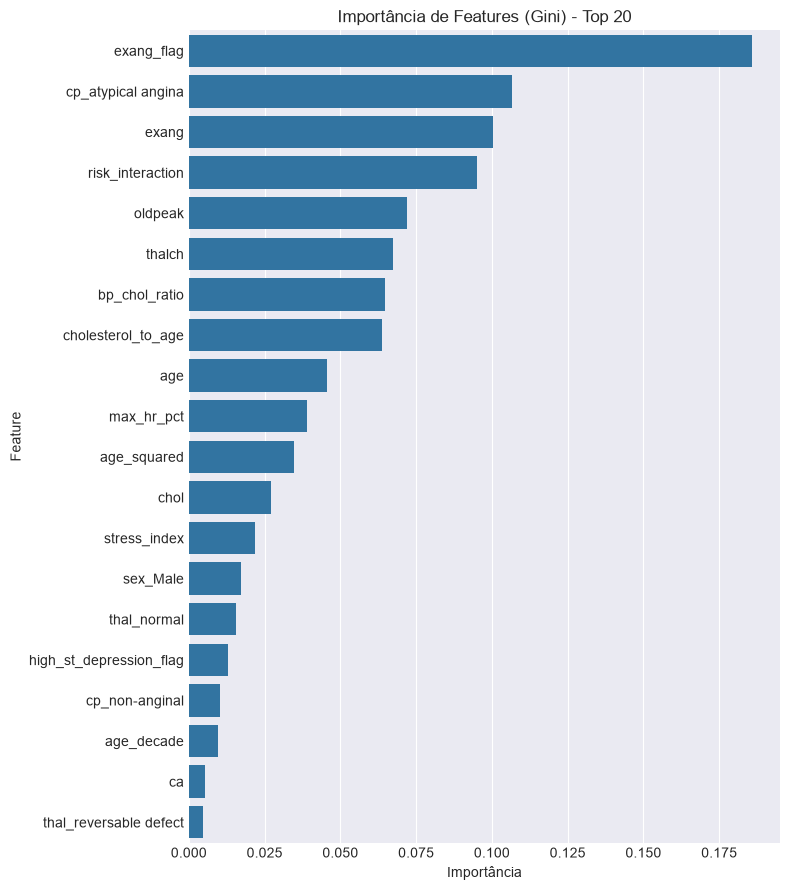

,feature,importance,std
26,risk_interaction,0.032609,0.014983
23,exang_flag,0.030435,0.011452
0,age,0.020652,0.007210
6,oldpeak,0.020652,0.006788
9,cp_atypical angina,0.019565,0.006960
19,cholesterol_to_age,0.019565,0.007762
4,thalch,0.019565,0.007762
18,age_squared,0.018478,0.006052
20,max_hr_pct,0.016848,0.006173
16,thal_normal,0.012500,0.005978


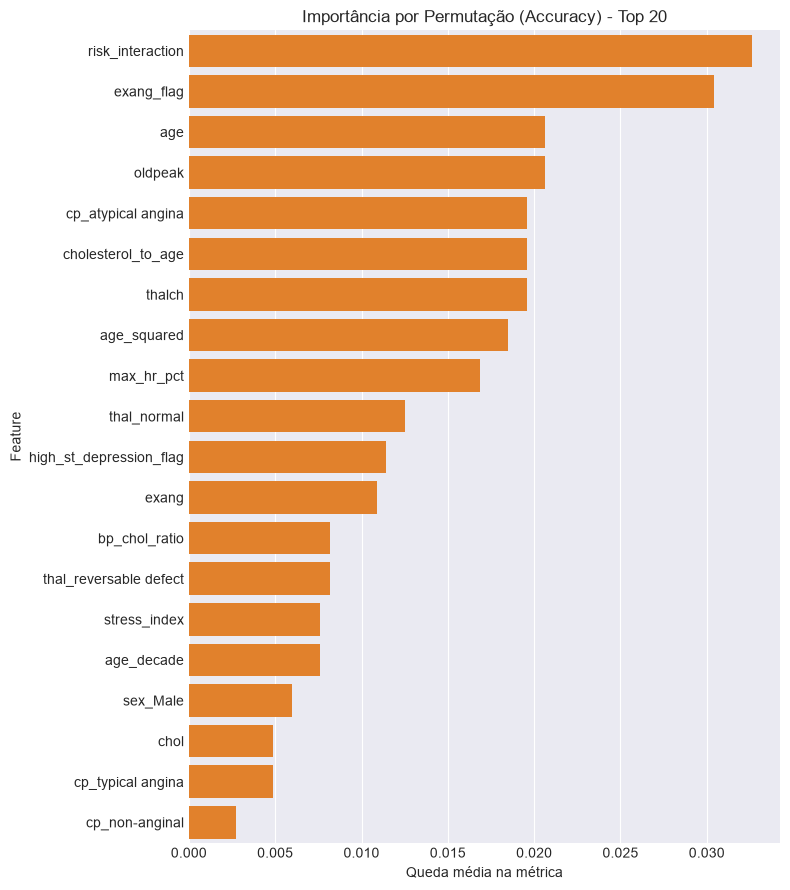

In [13]:
from datetime import datetime
import os
from sklearn.inspection import permutation_importance

print("== Importância de Features do Melhor Modelo ==")

assert "best_rf" in globals(), "best_rf não encontrado. Execute a seção de tuning antes."
assert "tuned_metrics" in globals(), "tuned_metrics não encontrado. Execute a seção de tuning antes."

# Extrair nomes de features utilizados pelo pipeline (após selector, se houver)
if hasattr(best_rf, "named_steps") and "selector" in best_rf.named_steps and hasattr(best_rf.named_steps["selector"], "get_support"):
    mask = best_rf.named_steps["selector"].get_support()
    feat_names_used = np.array(X_train.columns)[mask]
else:
    feat_names_used = np.array(X_train.columns)

model_step = best_rf.named_steps["model"] if hasattr(best_rf, "named_steps") and "model" in best_rf.named_steps else best_rf
tree_imp = getattr(model_step, "feature_importances_", None)

figs_to_log = []

if tree_imp is not None and len(tree_imp) == len(feat_names_used):
    imp_df = pd.DataFrame({"feature": feat_names_used, "importance": tree_imp}).sort_values("importance", ascending=False)
    display(imp_df.head(20))

    fig, ax = plt.subplots(figsize=(8, min(0.45*len(imp_df.head(20)), 10)))
    sns.barplot(data=imp_df.head(20), x="importance", y="feature", color="#1f77b4", ax=ax)
    ax.set_title("Importância de Features (Gini) - Top 20")
    ax.set_xlabel("Importância")
    ax.set_ylabel("Feature")
    plt.tight_layout()
    figs_to_log.append(("feature_importance_gini_top20.png", fig))
    plt.show()
else:
    print("[Info] Modelo não expõe feature_importances_. Pulando gráfico Gini.")

perm = permutation_importance(best_rf, X_test, y_test, scoring="accuracy", n_repeats=10, random_state=42, n_jobs=-1)
perm_df = pd.DataFrame({
    "feature": feat_names_used,
    "importance": perm.importances_mean,
    "std": perm.importances_std
}).sort_values("importance", ascending=False)
display(perm_df.head(20))

fig2, ax2 = plt.subplots(figsize=(8, min(0.45*len(perm_df.head(20)), 10)))
sns.barplot(data=perm_df.head(20), x="importance", y="feature", color="#ff7f0e", ax=ax2)
ax2.set_title("Importância por Permutação (Accuracy) - Top 20")
ax2.set_xlabel("Queda média na métrica")
ax2.set_ylabel("Feature")
plt.tight_layout()
figs_to_log.append(("feature_importance_permutation_top20.png", fig2))
plt.show()

In [18]:
models_dir = "models"
os.makedirs(models_dir, exist_ok=True)

joblib_path = os.path.join(models_dir, f"best_random_forest.joblib")
joblib.dump(best_rf, joblib_path)
print(f"Modelo salvo via joblib em: {joblib_path}")

mlflow.set_experiment("time_budget_tuning")
with mlflow.start_run(run_name="rf_importances_and_persistence"):
    if 'best' in globals() and isinstance(best.get('params'), dict):
        for k, v in best["params"].items():
            mlflow.log_param(k, str(v))
    for k, v in tuned_metrics.items():
        if v is not None and not (isinstance(v, float) and (np.isnan(v) or np.isinf(v))):
            mlflow.log_metric(k.replace(" ", "_").lower(), float(v))

    for fname, fobj in figs_to_log:
        try:
            mlflow.log_figure(fobj, fname)
        except Exception as e:
            print(f"[Aviso] Falha ao logar figura {fname}: {e}")

    mlflow.sklearn.log_model(
        best_rf,
        artifact_path="sklearn_model",
        skops_trusted_types=[
            "sklearn.feature_selection._univariate_selection.f_classif",
            "sklearn.tree._tree.Tree",
        ],
    )
    mlflow.log_artifact(joblib_path, artifact_path="joblib")

print("Concluído: importâncias, persistência (joblib) e log no MLflow.")

Modelo salvo via joblib em: models\best_random_forest.joblib


2026/11/07 14:36:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Concluído: importâncias, persistência (joblib) e log no MLflow.
